# 10 · Random Forest 与 LightGBM 预测相似性

[English](../../10_rf_lightgbm_similarity.ipynb) · 简体中文

本 notebook 只分析两组树模型在同一批 Test 记录上的逐行预测是否相同：

- E1：RF-logh 与 E3：LGBM-logh；
- E2：RF-p 与 E4：LGBM-p。

比较同时在模型原始输出空间和最终裁剪后的回忆率空间进行，并检查边界裁剪是否放大了表面相似性。这里不再包含 MAE/RMSE 误差分解；该分析已移至 `09_mae_rmse_analysis.ipynb`。

已有模型与统一 Test 预测会从缓存读取，不重新训练。


In [1]:
# Locate shared data and modules when running from a subdirectory.
from pathlib import Path
import os
import sys

_notebook_start = Path.cwd().resolve()
_notebook_parents = (_notebook_start, *_notebook_start.parents)
_project_root = next(
    (p for p in _notebook_parents
     if (p / "data/raw/settles.acl16.learning_traces.13m.csv.gz").is_file()),
    None,
)
if _project_root is None:
    _project_root = next(
        (p for p in _notebook_parents if (p / "experiment_pipeline.py").is_file()),
        _notebook_start,
    )
os.chdir(_project_root)
if str(_project_root) not in sys.path:
    sys.path.insert(0, str(_project_root))

from experiment_pipeline import Pipeline

run = Pipeline(language="zh-CN")
globals().update(run.rf_lgbm_similarity())


原始文件： D:\fujing123\Projects\Data-Analytic\HLR\data\raw\settles.acl16.learning_traces.13m.csv.gz
前 5 行：


,p_recall,timestamp,delta,user_id,learning_language,ui_language,lexeme_id,lexeme_string,history_seen,history_correct,session_seen,session_correct
0,1.0,1362076081,27649635,u:FO,de,en,76390c1350a8dac31186187e2fe1e178,lernt/lernen<vblex><pri><p3><sg>,6,4,2,2
1,0.5,1362076081,27649635,u:FO,de,en,7dfd7086f3671685e2cf1c1da72796d7,die/die<det><def><f><sg><nom>,4,4,2,1
2,1.0,1362076081,27649635,u:FO,de,en,35a54c25a2cda8127343f6a82e6f6b7d,mann/mann<n><m><sg><nom>,5,4,1,1
3,0.5,1362076081,27649635,u:FO,de,en,0cf63ffe3dda158bc3dbd55682b355ae,frau/frau<n><f><sg><nom>,6,5,2,1
4,1.0,1362076081,27649635,u:FO,de,en,84920990d78044db53c1b012f5bf9ab5,das/das<det><def><nt><sg><nom>,4,4,1,1


Reused saved duplicate check and cleaned dataset.


,raw_rows,exact_duplicates_removed,clean_rows
0,12854226,81,12854145


Model and EDA input: D:\fujing123\Projects\Data-Analytic\HLR\data\processed\settles.acl16.learning_traces.13m.dedup_v1.csv.gz


,split,start,stop_exclusive,rows
0,Train,0,9254984,9254984
1,Validation,9254984,11568730,2313746
2,Test,11568730,12854145,1285415


... (2 outputs left out)

Loaded rf results: D:\fujing123\Projects\Data-Analytic\HLR\data\artifacts\rf-63a752907e48a563.joblib
Loaded lgbm results: D:\fujing123\Projects\Data-Analytic\HLR\data\artifacts\lgbm-9ddfecffb33c8fce.joblib


,pair,space,n_test,Pearson,Spearman,mean_d,mean_abs_d,P50_abs_d,P90_abs_d,P99_abs_d,share_abs_lt_1e-6,share_exact
0,E1 vs E3,clipped_p,1285415,0.999839,0.999821,5.40839e-05,0.000677724,5.28721e-05,0.00146051,0.00942326,0.290873,0.23349
1,E1 vs E3,raw_log2_h,1285415,0.998481,0.9978,8.83455e-05,0.0158254,0.00819329,0.0279267,0.158902,0,0
2,E2 vs E4,clipped_p,1285415,0.976632,0.984299,7.59294e-06,0.00357975,0.00186114,0.00669609,0.0325417,0.000881427,0
3,E2 vs E4,raw_p,1285415,0.976632,0.984299,7.51957e-06,0.00357982,0.00186114,0.00669609,0.0325453,0.000881427,0


,pair,same_p_bound_share,n_both_interior,share_abs_lt_1e-6_interior
0,E1 vs E3,0.23349,983133,0.0740073
1,E2 vs E4,0,1285378,0.000881453


,pair,max_rebuild_error_RF,max_rebuild_error_LGBM
0,E1 vs E3,7.21645e-16,0
1,E2 vs E4,7.77156e-16,0


## 10.1 读表说明

`clipped_p` 是实际用于统一评价的最终回忆率预测；`raw_log2_h` 和 `raw_p` 是模型裁剪前的原始输出。Pearson 和 Spearman 接近 1 表示数值关系或排序高度接近，但不能证明逐行预测相同，因此还需同时查看平均绝对差异、差异分位数和完全相同比例。

`same_p_bound_share` 统计两个模型同时落在相同回忆率裁剪边界的比例。若它与 `share_exact` 一致，则最终预测的大量完全相等主要来自共同裁剪。重建误差用于确认原始模型输出可以准确还原第 7 节保存的 Test 预测。


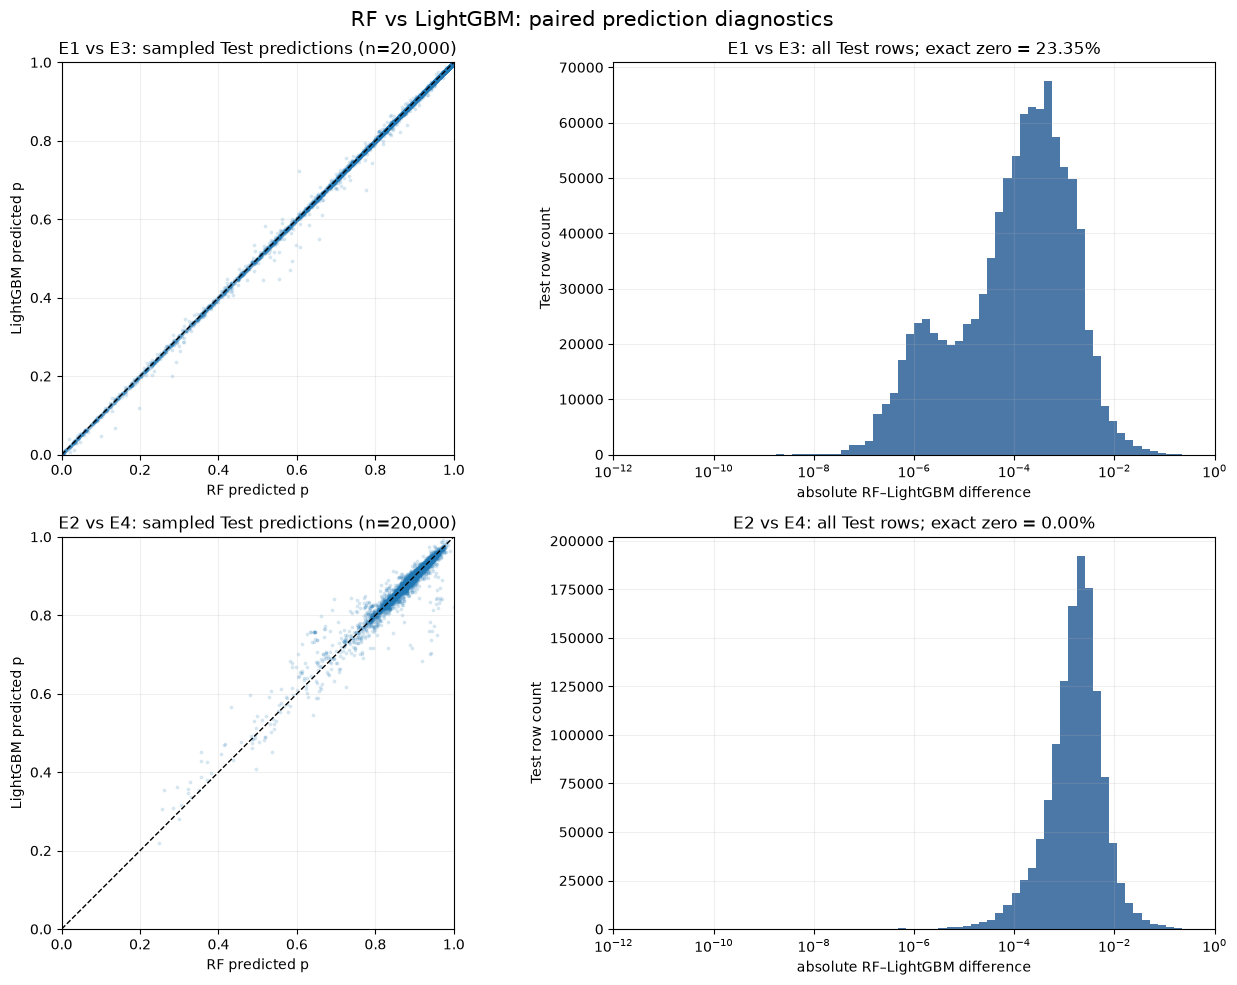

Saved: D:\fujing123\Projects\Data-Analytic\HLR\reports\s10_rf_lgbm_similarity.png


In [2]:
from pathlib import Path
import matplotlib.pyplot as plt

diag_scatter_n = min(20_000, diag_n_test)
diag_sample = np.random.default_rng(20261115).choice(
    diag_n_test, size=diag_scatter_n, replace=False
)
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for row, (pair, rf_name, lgb_name, *_rest) in enumerate(diag_pairs):
    rf_p = test_predictions[rf_name][0]
    lgb_p = test_predictions[lgb_name][0]
    ax_scatter, ax_hist = axes[row]
    ax_scatter.scatter(
        rf_p[diag_sample], lgb_p[diag_sample],
        s=7, alpha=0.18, linewidths=0, rasterized=True,
    )
    ax_scatter.plot([MIN_P, MAX_P], [MIN_P, MAX_P], 'k--', linewidth=1)
    ax_scatter.set(
        xlim=(0, 1), ylim=(0, 1),
        xlabel='RF predicted p', ylabel='LightGBM predicted p',
        title=f'{pair}: sampled Test predictions (n={diag_scatter_n:,})',
    )
    ax_scatter.set_aspect('equal', adjustable='box')
    ax_scatter.grid(alpha=0.2)

    abs_difference = np.abs(rf_p - lgb_p)
    positive = abs_difference[abs_difference > 0]
    ax_hist.hist(
        np.maximum(positive, 1e-12), bins=np.logspace(-12, 0, 75),
        color='#4C78A8', edgecolor='none',
    )
    ax_hist.set_xscale('log')
    ax_hist.set(
        xlim=(1e-12, 1), xlabel='absolute RF–LightGBM difference',
        ylabel='Test row count',
        title=f'{pair}: all Test rows; exact zero = {(abs_difference == 0).mean():.2%}',
    )
    ax_hist.grid(alpha=0.2)

fig.suptitle('RF vs LightGBM: paired prediction diagnostics', fontsize=15)
fig.tight_layout()
figure_path = Path('reports/s10_rf_lgbm_similarity.png')
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved: {figure_path.resolve()}')


## 10.2 结论

E1/E3 的最终回忆率预测几乎重合：Pearson 为 0.999839，平均绝对差异为 0.000678。不过，23.349% 的完全相同预测全部可以由两者共同落在相同裁剪边界解释；原始 `log2(h)` 输出没有逐行完全相等的记录。因此，两者的原始半衰期函数高度相关但并不相同，遗忘曲线变换和裁剪进一步放大了最终回忆率的相似性。

E2/E4 的 Pearson 为 0.976632，平均绝对差异为 0.003580。两者没有共同边界记录，也没有完全相同的 Test 预测，原始 `p` 和裁剪后 `p` 的差异统计几乎一致。因此，这一组的相似性来自模型实际输出，而不是裁剪。

综合来看，RF 与 LightGBM 在相同数据、特征和目标下学习到了高度相似的主要预测模式，但不能称为逐行等价。该诊断证明了相似程度及裁剪的作用；关于两种算法为什么收敛到相似模式，只能结合低维特征、大样本和共同目标作机制推断，不能视为已经完成因果证明。更完整的实验记录见 [最终报告](../../deliverables/ELEC3544_Group4_final_report.pdf)。
